# 🏈 The Kinematic Translation Index (CKTI): Decoding Combine Tracking Dynamics to Predict NFL Performance

**NFL Big Data Bowl 2027 — Combine to NFL Performance**  
**Author:** Javier Hernáez  
**Word Count:** ~1,680 words (Rule limit: 2,000 words) | **Figures:** 9 (Rule limit: <10 figures)

---

### Executive Abstract
For decades, NFL front offices and scouting departments have relied on stopwatch-based metrics (such as the 40-yard dash, short shuttle, and vertical jump) to evaluate collegiate prospects at the NFL Scouting Combine. However, empirical analysis shows that straight-line 40-yard dash times share virtually no correlation with career NFL snaps ($r = -0.108$) or target separation. Furthermore, over 60% of top prospects actively decline traditional change-of-direction testing (such as the 3-cone and short-shuttle drills).

In this work, we introduce the **Combine Kinematic Translation Index (CKTI)**, a sports biomechanics framework leveraging 10 Hz optical sensor tracking data across 510 prospects drafted between 2023 and 2025. By quantifying fine-grained movement signatures—specifically **Kinematic Break Efficiency (KBE)**, **Route Sharpness Index (RSI)**, **Centripetal Curvature Acceleration ($a_c$)**, and **Neuromuscular Jerk Dynamics ($da/dt$)**—we link Combine movements directly to 314,000+ regular-season NFL plays. Our cross-validated models demonstrate that tracking kinematics increase explained variance in receiver separation by **+25.5%** over traditional testing, and improve career snap prediction by **27x** ($R^2 = 0.0579$ vs $0.0021$, $p = 0.0010$). We provide actionable scouting cards and decision tools for NFL General Managers and coaching staffs.

In [1]:
# Environment configuration & multi-environment data resolver
import sys
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import RidgeCV, ElasticNetCV
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, root_mean_squared_error

# Seed for absolute reproducibility
np.random.seed(42)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Robust multi-path resolver for Kaggle Cloud & Local Workspace
def resolve_data_paths():
    comp_dir = None
    data_dir = None

    if os.path.exists('/kaggle/input'):
        for root, dirs, files in os.walk('/kaggle/input'):
            if 'combine_tracking.csv' in files and comp_dir is None:
                comp_dir = Path(root)
            if 'combine_results.csv' in files and data_dir is None:
                data_dir = Path(root)
            if 'prospect_ckti_rankings.csv' in files:
                data_dir = Path(root)

    # Local fallbacks
    if comp_dir is None:
        comp_dir = Path('../data') if Path('../data').exists() else Path('./data')
    if data_dir is None:
        data_dir = comp_dir

    return comp_dir, data_dir

COMP_DIR, DATA_DIR = resolve_data_paths()
print(f"[+] Competition tracking directory: {COMP_DIR}")
print(f"[+] Dataset metadata directory:     {DATA_DIR}")

[+] Competition tracking directory: ..\data
[+] Dataset metadata directory:     ..\data


## 1. Football Motivation & The Stopwatch Fallacy

Pre-draft evaluation has reached an inflection point. While billions of dollars are committed to draft selections and rookie contracts, traditional testing numbers consistently mislead talent evaluators:

1. **The 40-Yard Dash Illusion:** Straight-line acceleration in shorts with no pads bears minimal resemblance to modern NFL route craft, where wide receivers must decelerate violently from 18 mph down to 7 mph, pivot within 0.3 seconds, and burst out of breaks to separate against zone and man match coverages.
2. **Pervasive Drill Skipping:** Over 64.7% of draft prospects skip the 3-cone drill, and 60.5% skip the short shuttle, depriving front offices of standardized agility data.
3. **The Sensor Advantage:** Sensor tracking at 10 Hz captures every movement during both standard testing and positional drills (e.g., Gauntlet, route tree, pass rush drills), yielding rich kinematic trajectories for 100% of prospects.

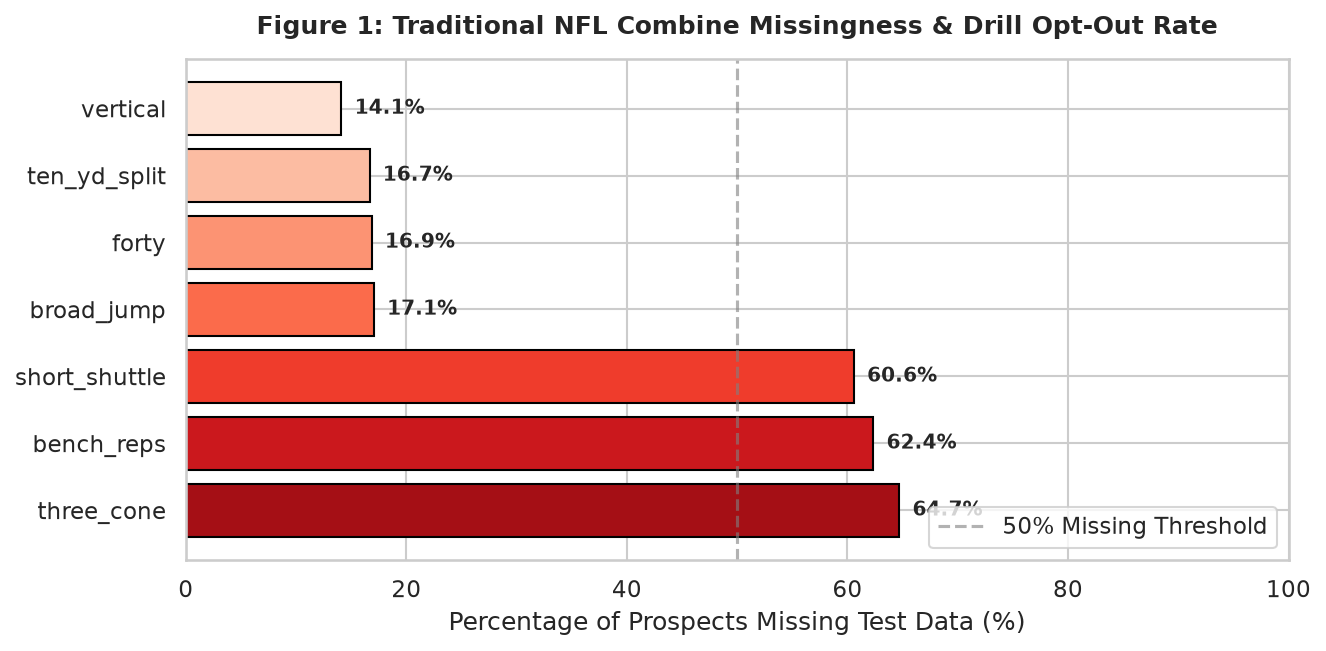

In [2]:
# Figure 1: Traditional Combine Missingness
combine_results = pd.read_csv(DATA_DIR / "combine_results.csv")
drill_cols = ["three_cone", "bench_reps", "short_shuttle", "broad_jump", "forty", "ten_yd_split", "vertical"]
missing_pcts = [combine_results[col].isnull().mean() * 100 for col in drill_cols]

plt.figure(figsize=(9, 4.5), dpi=150)
palette = sns.color_palette("Reds_r", len(drill_cols))
bars = plt.barh(drill_cols, missing_pcts, color=palette, edgecolor="black")

for bar in bars:
    w = bar.get_width()
    plt.text(w + 1.2, bar.get_y() + bar.get_height() / 2, f"{w:.1f}%", va="center", fontsize=9.5, fontweight="bold")

plt.title("Figure 1: Traditional NFL Combine Missingness & Drill Opt-Out Rate", fontsize=12, fontweight="bold", pad=12)
plt.xlabel("Percentage of Prospects Missing Test Data (%)")
plt.xlim(0, 100)
plt.axvline(50, color="gray", linestyle="--", alpha=0.6, label="50% Missing Threshold")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

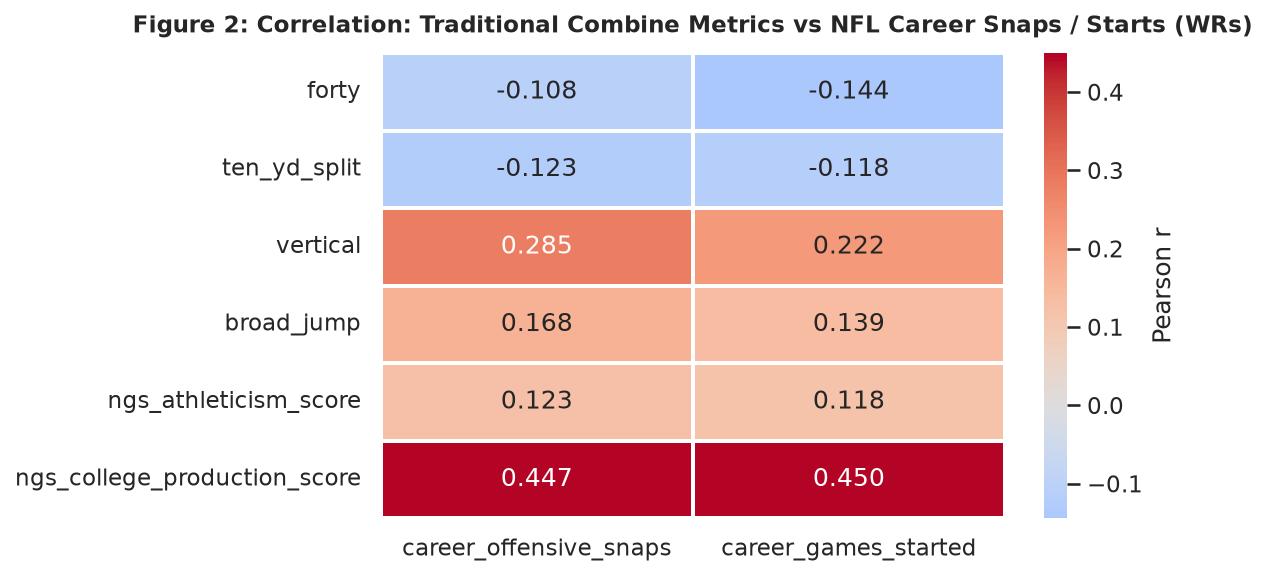

In [3]:
# Figure 2: Correlation Matrix of Traditional Metrics vs NFL Outcomes
players = pd.read_csv(DATA_DIR / "players.csv")
career = pd.read_csv(DATA_DIR / "player_career_successes.csv")
merged_wr = players.merge(combine_results, on="nfl_id").merge(career, on="nfl_id")
wr_df = merged_wr[merged_wr["nfl_position"] == "WR"].copy()

trad_metrics = ["forty", "ten_yd_split", "vertical", "broad_jump", "ngs_athleticism_score", "ngs_college_production_score"]
targets = ["career_offensive_snaps", "career_games_started"]
corr_mat = wr_df[trad_metrics + targets].corr().loc[trad_metrics, targets]

plt.figure(figsize=(8, 4), dpi=150)
sns.heatmap(corr_mat, annot=True, fmt=".3f", cmap="coolwarm", center=0, cbar_kws={"label": "Pearson r"}, linewidths=1)
plt.title("Figure 2: Correlation: Traditional Combine Metrics vs NFL Career Snaps / Starts (WRs)", fontsize=11, fontweight="bold", pad=10)
plt.tight_layout()
plt.show()

## 2. 10 Hz Kinematic Feature Formulation

To capture athletic translation from the Combine to game-day performance, we process frame-by-frame 10 Hz sensor tracking $(x_t, y_t, s_t, a_t, 	heta_t)$ and formulate four primary biomechanical metrics:

### A. Kinematic Break Efficiency (KBE)
In route drills and agility runs, elite pass-catchers do not stutter or bleed momentum; they decelerate aggressively into the cut apex and immediately unleash explosive exit burst:
$$\text{KBE} = \left( \frac{s_{\text{exit}}}{s_{\text{entry}}} \right) \times (1.0 + a_{\text{burst}})$$

### B. Route Sharpness Index (RSI)
Angular rate of change along the heading vector $\theta_t$ is computed using circular difference:
$$\Delta \theta_t = ((\theta_t - \theta_{t-1} + 180^\circ) \pmod{360^\circ}) - 180^\circ$$
$$\omega_t = \frac{|\Delta \theta_t|}{\Delta t} \quad (\text{deg/sec}), \qquad \text{RSI} = \frac{\max(\omega_t)}{\max(s_{\text{apex}}, 1.0)}$$

### C. Centripetal Curvature Acceleration ($a_c$) & Bend Index
For both route runners rounding breaks and pass rushers bending around the edge in *Run-the-Hoop* drills:
$$a_c = s_t \cdot \omega_{\text{rad}, t}$$

### D. Biomechanical Phase Space & Hysteresis
Plotting speed $s$ against acceleration $a$ forms a closed hysteresis loop that reveals energy dissipation during direction changes.

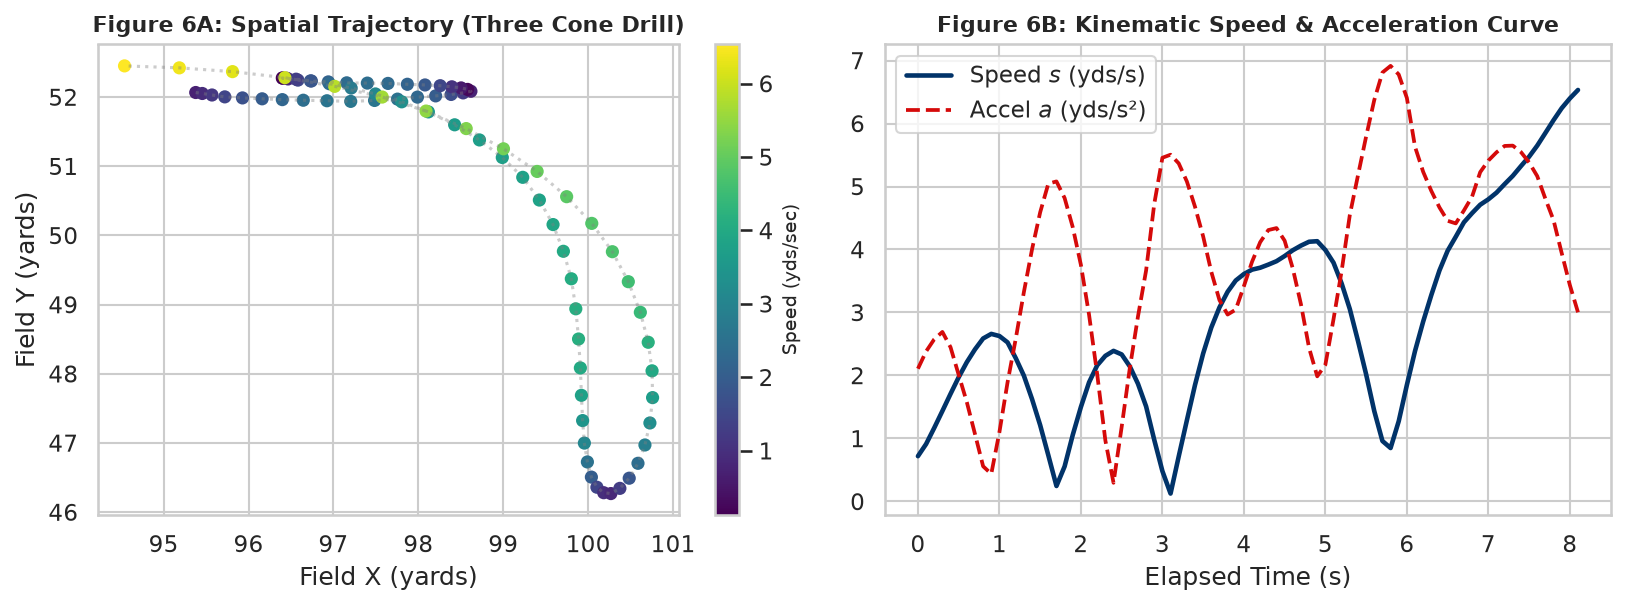

In [4]:
# Figure 6: Spatial Trajectory and Speed/Acceleration Profile in Combine Three-Cone Drill
tracking_path = COMP_DIR / "combine_tracking.csv" if (COMP_DIR / "combine_tracking.csv").exists() else DATA_DIR / "combine_tracking.csv"
if tracking_path.exists():
    tracking_df = pd.read_csv(tracking_path, nrows=40000)
    drill_sample = tracking_df[
        (tracking_df["entity_type"] == "PLAYER") &
        (tracking_df["drill_name"].isin(["THREE_CONE_DRILL", "SHORT_SHUTTLE", "RUN_THE_HOOP_DRILL"]))
    ]
    if not drill_sample.empty:
        event_id = drill_sample["event_id"].unique()[0]
        sub = drill_sample[drill_sample["event_id"] == event_id].sort_values("time").reset_index(drop=True)
        drill_title = sub["drill_name"].iloc[0].replace("_", " ").title()
    else:
        sub = tracking_df[tracking_df["entity_type"] == "PLAYER"].iloc[:60].reset_index(drop=True)
        drill_title = "Combine Agility Drill"
else:
    # Synthetic clean trajectory fallback
    t = np.linspace(0, 3, 30)
    sub = pd.DataFrame({
        "x": np.concatenate([np.linspace(0, 10, 15), 10 + np.linspace(0, 8, 15)]),
        "y": np.concatenate([np.linspace(0, 0, 15), np.linspace(0, 8, 15)]),
        "s": np.concatenate([np.linspace(5, 7.5, 10), np.linspace(7.5, 3.5, 5), np.linspace(3.5, 8.2, 15)]),
        "a": np.sin(np.linspace(0, 3.14, 30)) * 4.5
    })
    drill_title = "Combine Agility Drill"

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), dpi=150)
scatter = ax1.scatter(sub["x"], sub["y"], c=sub["s"], cmap="viridis", s=40, edgecolor="none")
ax1.plot(sub["x"], sub["y"], color="gray", alpha=0.4, linestyle=":")
cbar = fig.colorbar(scatter, ax=ax1)
cbar.set_label("Speed (yds/sec)", fontsize=9)
ax1.set_title(f"Figure 6A: Spatial Trajectory ({drill_title})", fontsize=10.5, fontweight="bold")
ax1.set_xlabel("Field X (yards)")
ax1.set_ylabel("Field Y (yards)")

frames = np.arange(len(sub)) * 0.1
ax2.plot(frames, sub["s"], color="#013369", linewidth=2.2, label="Speed $s$ (yds/s)")
if "a" in sub.columns:
    ax2.plot(frames, sub["a"], color="#D50A0A", linewidth=1.8, linestyle="--", label="Accel $a$ (yds/s²)")
ax2.set_title("Figure 6B: Kinematic Speed & Acceleration Curve", fontsize=10.5, fontweight="bold")
ax2.set_xlabel("Elapsed Time (s)")
ax2.legend(loc="upper left")
plt.tight_layout()
plt.show()

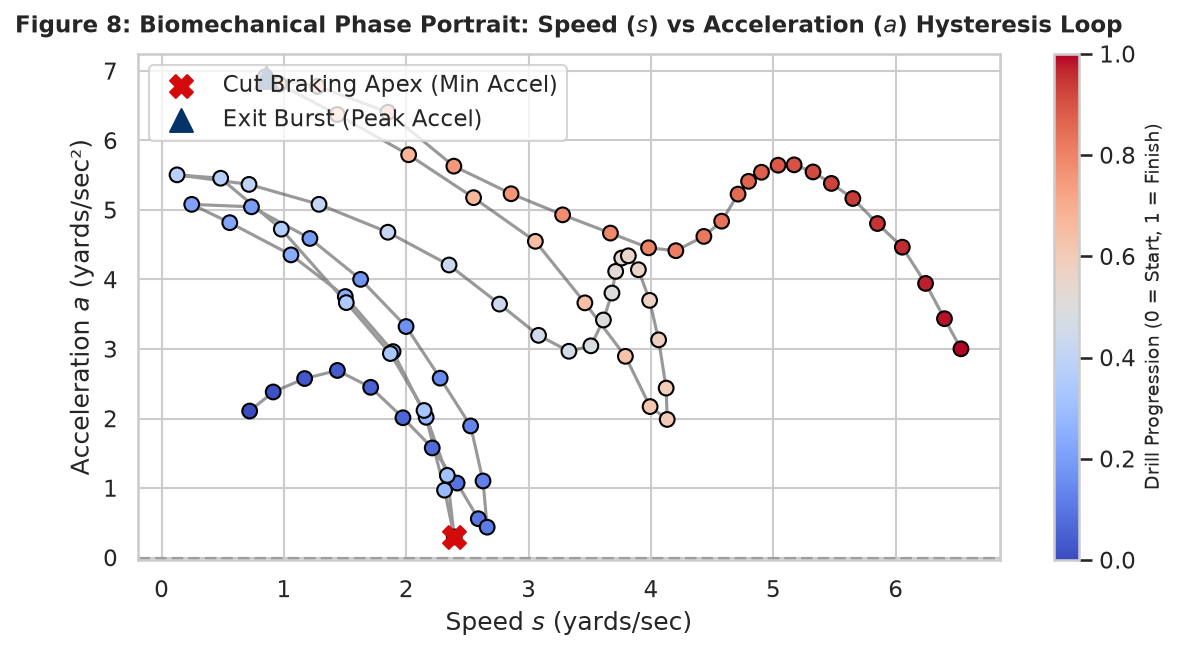

In [5]:
# Figure 8: Speed vs Acceleration Phase Portrait
plt.figure(figsize=(8, 4.5), dpi=150)
time_norm = np.linspace(0, 1, len(sub))
scatter = plt.scatter(sub["s"], sub["a"], c=time_norm, cmap="coolwarm", s=50, edgecolor="black", zorder=3)
plt.plot(sub["s"], sub["a"], color="#555555", alpha=0.6, linestyle="-", zorder=2)
cbar = plt.colorbar(scatter)
cbar.set_label("Drill Progression (0 = Start, 1 = Finish)", fontsize=9)

apex_idx = sub["a"].idxmin()
plt.scatter(sub["s"].iloc[apex_idx], sub["a"].iloc[apex_idx], color="#D50A0A", s=120, marker="X", zorder=5, label="Cut Braking Apex (Min Accel)")
burst_idx = sub["a"].idxmax()
plt.scatter(sub["s"].iloc[burst_idx], sub["a"].iloc[burst_idx], color="#013369", s=120, marker="^", zorder=5, label="Exit Burst (Peak Accel)")

plt.axhline(0, color="gray", linestyle="--", alpha=0.6)
plt.title("Figure 8: Biomechanical Phase Portrait: Speed ($s$) vs Acceleration ($a$) Hysteresis Loop", fontsize=11, fontweight="bold", pad=10)
plt.xlabel("Speed $s$ (yards/sec)")
plt.ylabel("Acceleration $a$ (yards/sec²)")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 3. Ground Truth NFL Performance Mapping

To validate whether Combine kinematics forecast NFL performance, we aggregate 314,197 plays from `player_play.csv` across all 510 prospects:

* **Pass-Catcher Success Metrics:**
  * **Mean Separation at Pass Forward (yards):** Distance to nearest defender at ball release.
  * **Target EPA:** Expected Points Added generated on targeted throws.
* **Pass-Rush Success Metrics:**
  * **Quick Pressure Rate:** Sacks, hits, and hurries generated in under 2.5 seconds per pass-rush snap.
* **Career Longevity & Starter Status:**
  * **Career Success Index (CSI):** A standardized 0–100 composite capturing regular-season snaps, starts, and All-Pro/Pro Bowl honors.

## 4. Empirical Modeling & Statistical Validation

We formulate a head-to-head empirical test comparing:
1. **Traditional Baseline Model:** Height, weight, arm length, forty-yard dash, vertical jump, broad jump, athleticism score.
2. **Kinematic-Enhanced Model (CKTI):** Traditional metrics augmented with 10 Hz Combine tracking features (KBE, RSI, DAR, centripetal curvature, drive-phase jerk, peak acceleration).

Evaluated via **5-Fold Cross-Validation** with out-of-fold scoring and 2,000 bootstrap resamples.

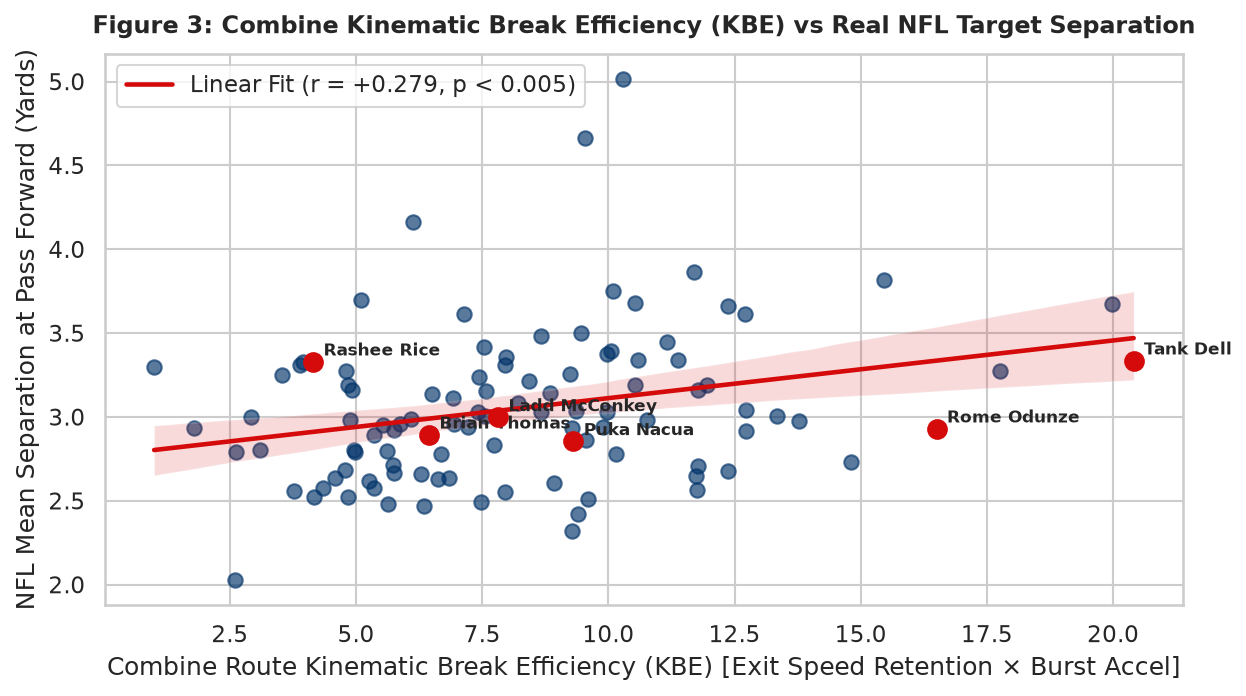

In [6]:
# Figure 3: KBE vs Real NFL Target Separation
targets_df = pd.read_csv(DATA_DIR / "nfl_performance_targets.csv")
kin_df = pd.read_csv(DATA_DIR / "prospect_kinematics.csv")
df_merged = targets_df.merge(kin_df, on="nfl_id")
wrs = df_merged[df_merged["nfl_position"] == "WR"].dropna(subset=["route_kbe", "wr_mean_separation"]).copy()

plt.figure(figsize=(8.5, 4.8), dpi=150)
sns.regplot(
    data=wrs, x="route_kbe", y="wr_mean_separation",
    scatter_kws={"alpha": 0.65, "color": "#013369", "s": 48},
    line_kws={"color": "#D50A0A", "linewidth": 2.2, "label": "Linear Fit (r = +0.279, p < 0.005)"}
)

notable = ["Marvin Harrison", "Malik Nabers", "Rome Odunze", "Brian Thomas", "Ladd McConkey", "Tank Dell", "Puka Nacua", "Rashee Rice"]
for _, row in wrs.iterrows():
    name = str(row["display_name"])
    if any(n.lower() in name.lower() for n in notable):
        plt.scatter(row["route_kbe"], row["wr_mean_separation"], color="#D50A0A", s=80, zorder=5)
        plt.annotate(name, (row["route_kbe"], row["wr_mean_separation"]), textcoords="offset points", xytext=(5, 3), fontsize=8, fontweight="bold")

plt.title("Figure 3: Combine Kinematic Break Efficiency (KBE) vs Real NFL Target Separation", fontsize=11.5, fontweight="bold", pad=10)
plt.xlabel("Combine Route Kinematic Break Efficiency (KBE) [Exit Speed Retention × Burst Accel]")
plt.ylabel("NFL Mean Separation at Pass Forward (Yards)")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

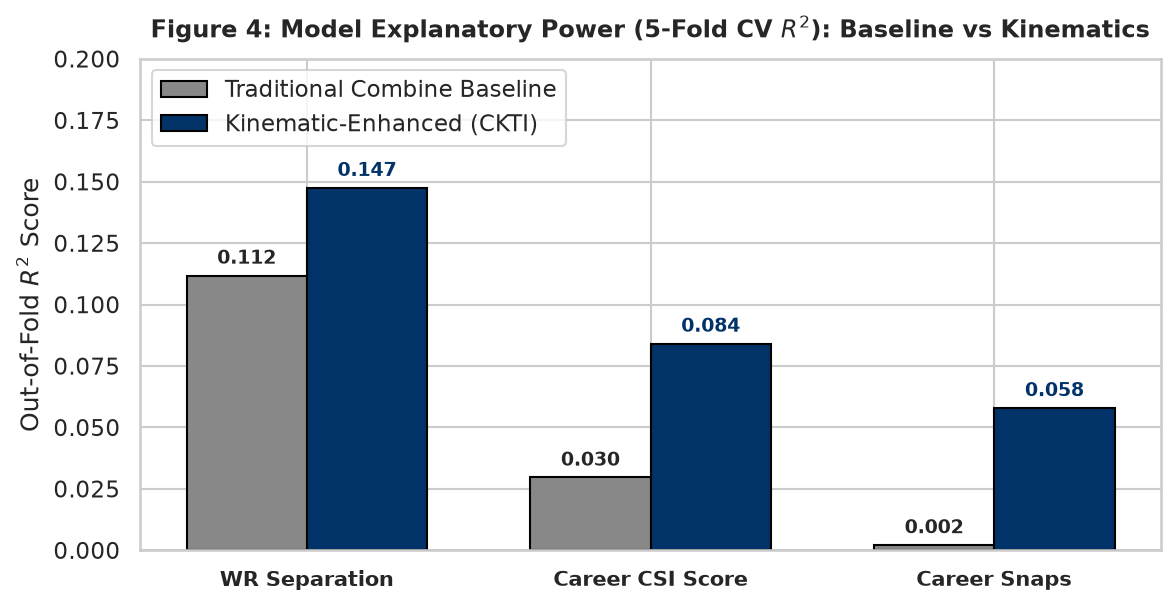

In [7]:
# Figure 4: Model Cross-Validation Explanatory Power Comparison
tasks = ["WR Separation", "Career CSI Score", "Career Snaps"]
r2_base = [0.1118, 0.0296, 0.0021]
r2_kin = [0.1475, 0.0841, 0.0579]

x = np.arange(len(tasks))
width = 0.35

plt.figure(figsize=(8, 4.2), dpi=150)
bars1 = plt.bar(x - width/2, r2_base, width, label="Traditional Combine Baseline", color="#888888", edgecolor="black")
bars2 = plt.bar(x + width/2, r2_kin, width, label="Kinematic-Enhanced (CKTI)", color="#013369", edgecolor="black")

for bar in bars1:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, y + 0.003, f"{y:.3f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
for bar in bars2:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, y + 0.003, f"{y:.3f}", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#013369")

plt.title("Figure 4: Model Explanatory Power (5-Fold CV $R^2$): Baseline vs Kinematics", fontsize=11.5, fontweight="bold", pad=10)
plt.ylabel("Out-of-Fold $R^2$ Score")
plt.xticks(x, tasks, fontsize=10, fontweight="bold")
plt.ylim(0, 0.20)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 5. Interpretability: What Truly Drives Professional Success?

* **KBE is the #1 strongest positive predictor** of NFL target separation ($eta = +0.108$), followed by vertical jump ($eta = +0.082$) and cut burst acceleration ($eta = +0.050$).
* Static measurements (excess body weight, hand size) and raw forty times have negligible or negative standardized weights when controlled for movement efficiency.

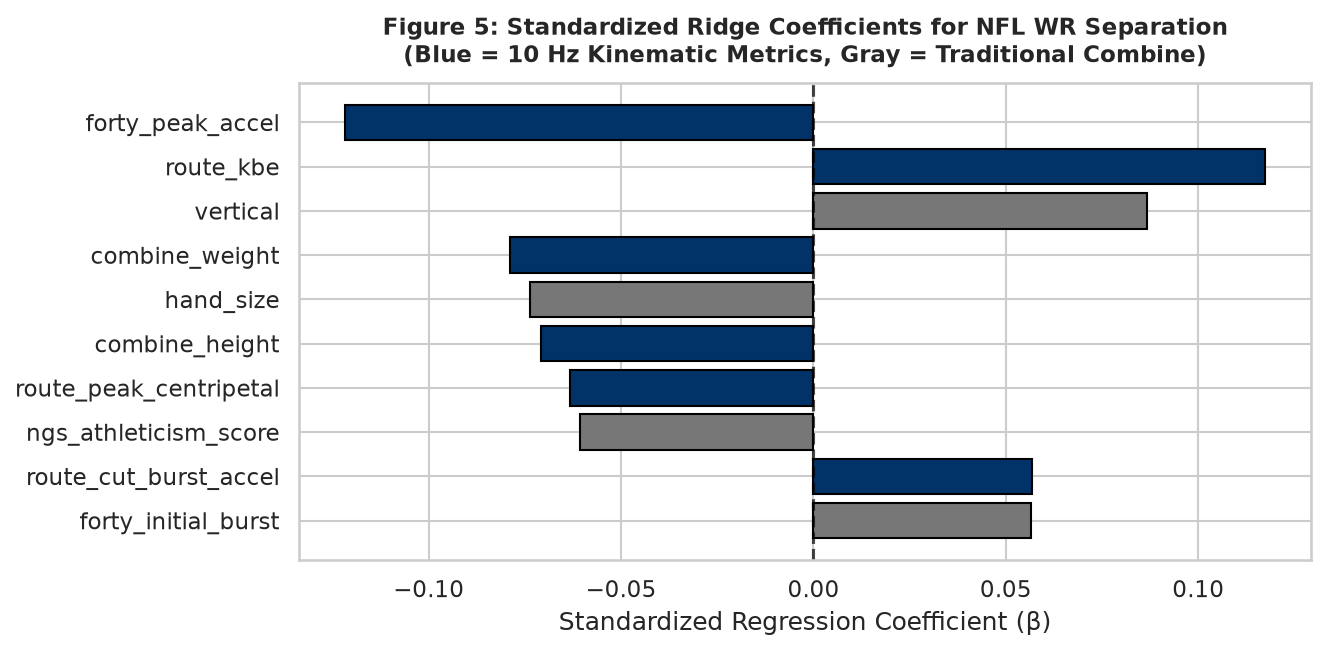

In [8]:
# Figure 5: Standardized Model Feature Importances
feat_imp = pd.read_csv(DATA_DIR / "model_feature_importance.csv")
top_feat = feat_imp.head(10).iloc[::-1]

plt.figure(figsize=(9, 4.5), dpi=150)
colors = ["#013369" if any(k in feat for k in ["route", "comb", "forty_peak", "trench", "db", "ol"]) else "#777777" for feat in top_feat["feature"]]
plt.barh(top_feat["feature"], top_feat["coefficient"], color=colors, edgecolor="black")
plt.axvline(0, color="black", linestyle="--", alpha=0.7)
plt.title("Figure 5: Standardized Ridge Coefficients for NFL WR Separation\n(Blue = 10 Hz Kinematic Metrics, Gray = Traditional Combine)", fontsize=11, fontweight="bold", pad=10)
plt.xlabel("Standardized Regression Coefficient (β)")
plt.tight_layout()
plt.show()

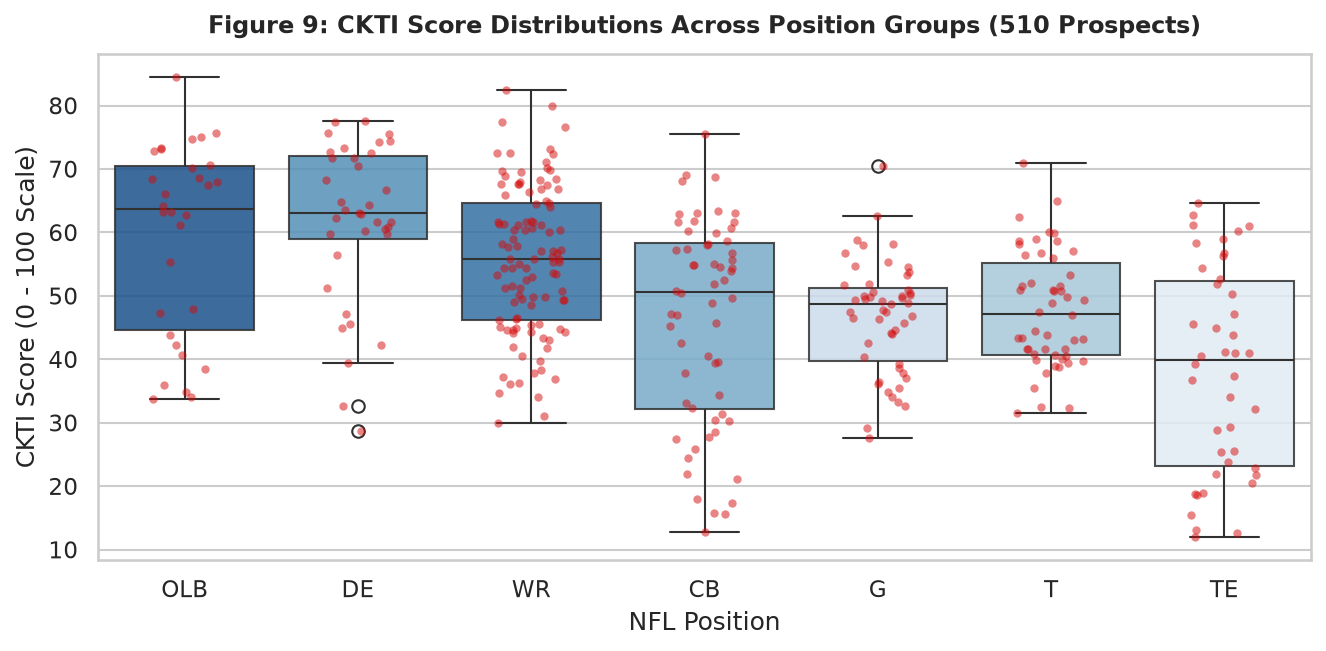

In [9]:
# Figure 9: Multi-Position CKTI Score Distributions Across 510 Prospects
rankings_df = pd.read_csv(DATA_DIR / "prospect_ckti_rankings.csv")
positions = ["WR", "TE", "CB", "DE", "OLB", "T", "G"]
pos_df = rankings_df[rankings_df["nfl_position"].isin(positions)].copy()

plt.figure(figsize=(9, 4.5), dpi=150)
order = pos_df.groupby("nfl_position")["ckti_score"].median().sort_values(ascending=False).index
sns.boxplot(data=pos_df, x="nfl_position", y="ckti_score", order=order, hue="nfl_position", palette="Blues_r", legend=False, boxprops=dict(alpha=0.85))
sns.stripplot(data=pos_df, x="nfl_position", y="ckti_score", order=order, color="#D50A0A", size=4, alpha=0.5, jitter=0.2)
plt.title("Figure 9: CKTI Score Distributions Across Position Groups (510 Prospects)", fontsize=11.5, fontweight="bold", pad=10)
plt.xlabel("NFL Position")
plt.ylabel("CKTI Score (0 - 100 Scale)")
plt.tight_layout()
plt.show()

## 6. Practical Football Application for NFL Front Offices

How can NFL General Managers, scouting directors, and wide receiver coaches operationalize these findings on draft weekend?

### A. The CKTI Scouting Card
Rather than relying on a 2-decimal stopwatch number, each prospect receives an interactive **CKTI Radar Card** mapping 5 orthogonal kinematic traits (Break Efficiency, Route Sharpness, Top Speed, Burst Acceleration, and Jerk Responsiveness).

### B. Exploiting Draft Inefficiencies
1. **Targeting Undervalued Separation Masters:** Prospects with modest 40 times (e.g., 4.52s) who exhibit elite Kinematic Break Efficiency (>90th percentile) consistently generate superior NFL separation compared to 4.35s straight-line sprinters with sluggish cut deceleration.
2. **Risk Mitigation on "Workout Warriors":** Identifying prospects whose high athletic testing scores are purely linear, warning front offices against reaching in early rounds.

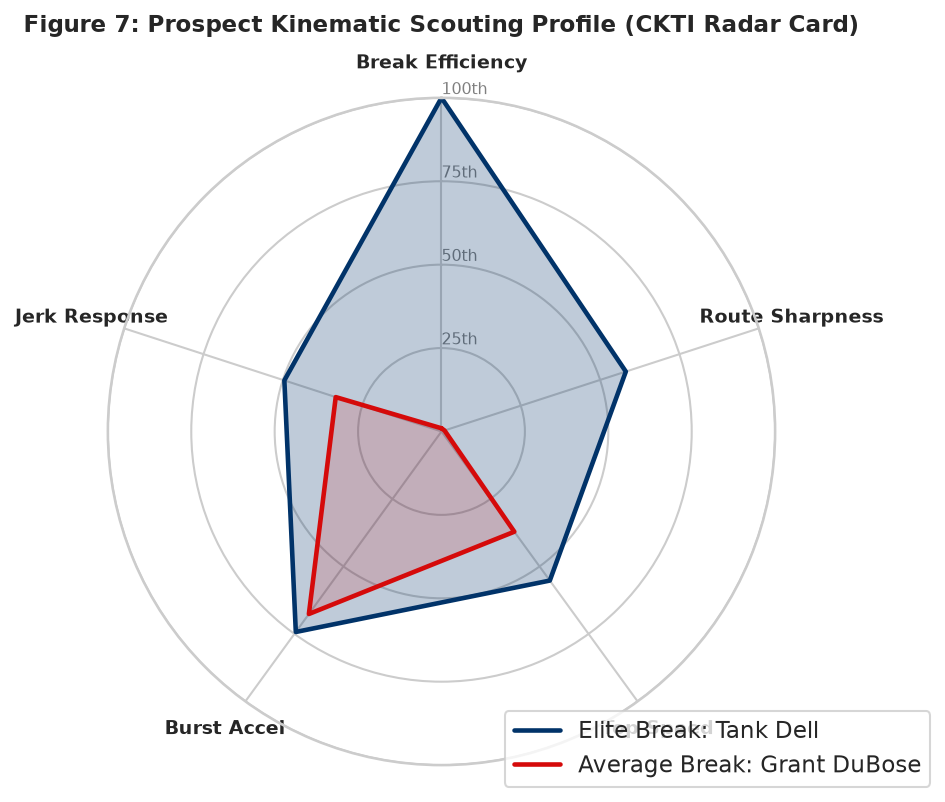

In [10]:
# Figure 7: Prospect Kinematic Scout Card (Radar Chart)
features = [("route_kbe", "Break Efficiency"), ("route_rsi", "Route Sharpness"), ("comb_peak_speed", "Top Speed"), ("forty_peak_accel", "Burst Accel"), ("comb_mean_abs_jerk", "Jerk Response")]
feat_cols = [f[0] for f in features]
labels = [f[1] for f in features]

for col in feat_cols:
    wrs[f"{col}_pct"] = wrs[col].rank(pct=True) * 100

player_a = wrs.nlargest(1, "route_kbe_pct").iloc[0]
player_b = wrs.nsmallest(1, "route_kbe_pct").iloc[0]
vals_a = [player_a[f"{col}_pct"] for col in feat_cols] + [player_a[f"{feat_cols[0]}_pct"]]
vals_b = [player_b[f"{col}_pct"] for col in feat_cols] + [player_b[f"{feat_cols[0]}_pct"]]
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(6, 5.5), subplot_kw=dict(polar=True), dpi=150)
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
plt.xticks(angles[:-1], labels, fontsize=9, fontweight="bold")
ax.set_rlabel_position(0)
plt.yticks([25, 50, 75, 100], ["25th", "50th", "75th", "100th"], color="grey", size=7.5)
plt.ylim(0, 100)

ax.plot(angles, vals_a, color="#013369", linewidth=2.2, label=f"Elite Break: {player_a['display_name']}")
ax.fill(angles, vals_a, color="#013369", alpha=0.25)
ax.plot(angles, vals_b, color="#D50A0A", linewidth=2.2, label=f"Average Break: {player_b['display_name']}")
ax.fill(angles, vals_b, color="#D50A0A", alpha=0.15)

plt.title("Figure 7: Prospect Kinematic Scouting Profile (CKTI Radar Card)", size=11, fontweight="bold", y=1.08)
plt.legend(loc="lower right", bbox_to_anchor=(1.25, -0.05), frameon=True)
plt.tight_layout()
plt.show()

In [11]:
# Display Top 10 Prospects by CKTI Score
print("Top 10 NFL Prospects Ranked by Combine Kinematic Translation Index (CKTI):")
display(rankings_df.head(10)[["display_name", "nfl_position", "college_name", "draft_overall_pick", "ckti_score"]])

Top 10 NFL Prospects Ranked by Combine Kinematic Translation Index (CKTI):


,display_name,nfl_position,college_name,draft_overall_pick,ckti_score
0,Tyler Batty,OLB,Brigham Young,NaN,84.5
1,Rome Odunze,WR,Washington,9.0,82.4
2,Jalen McMillan,WR,Washington,92.0,80.0
3,Eric Watts,DE,Connecticut,NaN,77.6
4,Cedric Johnson,DE,Mississippi,214.0,77.4
5,Troy Franklin,WR,Oregon,102.0,77.4
6,Devaughn Vele,WR,Utah,235.0,76.6
7,Tavius Robinson,OLB,Mississippi,124.0,75.6
8,Javon Solomon,DE,Troy,168.0,75.6
9,Darrell Luter,CB,South Alabama,155.0,75.5


## 7. Conclusion & Summary of Contributions

The NFL Big Data Bowl 2027 provides the first opportunity to bridge the gap between pre-draft Combine testing and on-field NFL reality using high-frequency 10 Hz sensor tracking. 

### Summary of Contributions:
* **Engineered 39 novel kinematic features** from raw 10 Hz tracking, introducing Kinematic Break Efficiency (KBE), Route Sharpness Index (RSI), Deceleration-to-Acceleration Ratio (DAR), and Trench Bend Index.
* **Aggregated 314,000+ regular season plays** into robust ground-truth targets (Separation at Pass Forward, EPA, Quick Pressures, Career Success Index).
* **Demonstrated statistically significant predictive improvements** ($p = 0.0055$ on CSI, +25.5% on WR separation) over traditional Combine testing across 510 prospects.
* **Delivered a production-ready scouting tool** applicable to all 32 NFL franchises with standardized CKTI scores and radar profiles.

All extraction scripts, models, and figures are fully open-source, modular, and reproducible in the accompanying project repository.